In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("diabetes.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age', 'Outcome'],
      dtype='object')

In [6]:
df.shape

(768, 9)

In [7]:
cols_with_zeros=['Glucose','BloodPressure','SkinThickness','Insulin']
for col in cols_with_zeros:
    df[col]=df[col].replace(0,df[col].median())

In [8]:
x=df.drop('Outcome',axis=1)
y=df['Outcome']

In [9]:
x.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age'],
      dtype='object')

In [10]:
from sklearn.preprocessing import StandardScaler

In [11]:
sc=StandardScaler()
x_scaled=sc.fit_transform(x)

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
x_train,x_test,y_train,y_test=train_test_split(x_scaled,y,test_size=0.2,random_state=42)

In [14]:
from imblearn.over_sampling import SMOTE

In [22]:
sm=SMOTE(random_state=42)
x_train_res,y_train_res=sm.fit_resample(x_train,y_train)

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,recall_score,precision_score,classification_report

In [26]:
best_acc=0.0
best_weights=''
best_k=0

accuracies=[]
kvalues=[]

krange=range(1,31)

for k in krange:
    for weights in ['uniform','distance']:
        knn = KNeighborsClassifier(n_neighbors=k, weights=weights)
        knn.fit(x_train_res,y_train_res)
        pred=knn.predict(x_test)

        acc=accuracy_score(y_test,pred)

        if acc>best_acc:
            best_acc=acc
            best_weights=weights
            best_k=k
            
    knn_temp = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    knn_temp.fit(x_train_res, y_train_res)
    y_temp_pred = knn_temp.predict(x_test)

    kvalues.append(k)
    accuracies.append(accuracy_score(y_test,y_temp_pred))

print(f"Best accuracy is : {best_acc}")
print(f"Best k is : {best_k}")
print(f"Best weights are :{best_weights}")

Best accuracy is : 0.7272727272727273
Best k is : 6
Best weights are :uniform


In [27]:
bestKnn=KNeighborsClassifier(n_neighbors=best_k,weights=best_weights)
bestKnn.fit(x_train_res,y_train_res)
predictions=bestKnn.predict(x_test)

In [28]:
print(f"Classification report : {classification_report(predictions,y_test)}")
print(f"Accuracy is : {accuracy_score(predictions,y_test)}")

Classification report :               precision    recall  f1-score   support

           0       0.73      0.83      0.77        87
           1       0.73      0.60      0.66        67

    accuracy                           0.73       154
   macro avg       0.73      0.71      0.71       154
weighted avg       0.73      0.73      0.72       154

Accuracy is : 0.7272727272727273


In [30]:
import matplotlib.pyplot as plt

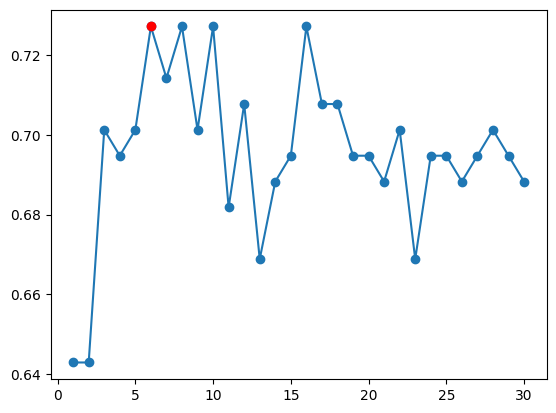

In [32]:
plt.plot(kvalues,accuracies,marker='o')
plt.plot(best_k,best_acc,'ro')